# LAB03 - Bayes and kNN Classificators
from scratch!

## Data prep

In [1]:
from google.colab import drive
drive.mount('/content/drive')

!pip install rasterio -q

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import rasterio
from pathlib import Path

Mounted at /content/drive


Setting the paths to the data (using mosty data from previous lab which is Sentinel-2 imagery of Krakow acquired on 27th of October 2026 in bands B02, B03, B04 and B08). I have added the "test" folder, which contains the same bands for imagery containing easternmost part of Kraków as well as Niepołomice and Wieliczka. There is Puszcza Niepołomicka forest which will be perfect for quality test of forest classification.

In [34]:
DATA = Path("/content/drive/MyDrive/ml_lab2_data")
BANDS = ["B02", "B03", "B04", "B08"]
FOLDERS = ["urban", "test"]

def band_path(folder, band):
    return DATA / folder / f"sentinel2_{band.lower()}.tiff"

Let's load the images and visualize them

In [35]:
def load_image(folder):
    """Loads all bands of one image into an array of shape (rows, cols, bands)."""
    layers = []
    for b in BANDS:
        with rasterio.open(band_path(folder, b)) as src:
            layers.append(src.read(1).astype(float))
    return np.stack(layers, axis=-1)

images = {folder: load_image(folder) for folder in FOLDERS}

for folder, img in images.items():
    print(f"{folder:8} shape: {img.shape}")

urban    shape: (1032, 1292, 4)
test     shape: (1820, 2500, 4)


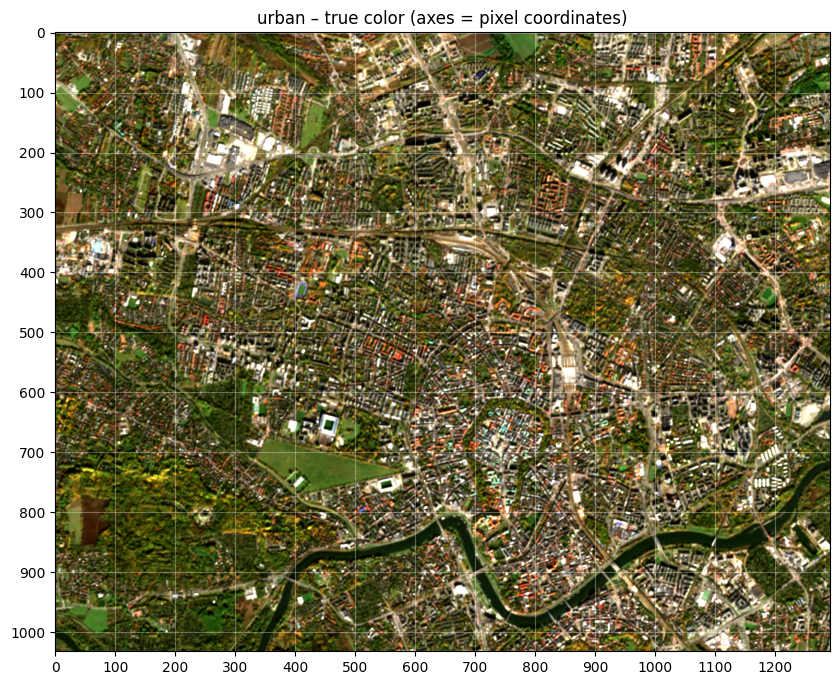

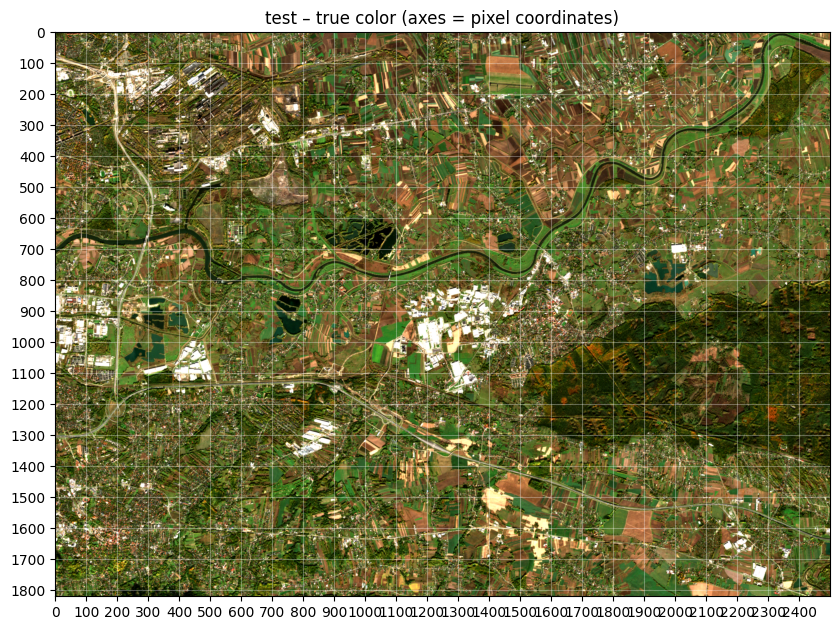

In [36]:
def to_rgb(img):
    """True color composite (B04, B03, B02) with a contrast stretch, for display only."""
    rgb = img[..., [2, 1, 0]]
    lo, hi = np.percentile(rgb, [2, 98])
    return np.clip((rgb - lo) / (hi - lo), 0, 1)

for folder, img in images.items():
    fig, ax = plt.subplots(figsize=(10, 10))
    ax.imshow(to_rgb(img))
    ax.set_xticks(np.arange(0, img.shape[1], 100))
    ax.set_yticks(np.arange(0, img.shape[0], 100))
    ax.grid(color='white', alpha=0.3)
    ax.set_title(f"{folder} – true color (axes = pixel coordinates)")
    plt.show()

Now it's time to define my training areas

In [44]:
# ("image", row_start, row_end, col_start, col_end)
train_areas = {
    "forest": [("urban", 800, 880, 100, 150),
               ("urban", 620, 660, 260, 320),
               ("urban", 870, 900, 1150, 1200)],
    "urban":  [("urban", 650, 700, 750, 800),
               ("urban", 170, 220, 250, 320),
               ("urban", 450, 500, 250, 330)],
}

val_areas = {
    "forest": [("urban", 850, 900, 200, 250)],
    "urban":  [("urban", 850, 900, 800, 870)],
}

For this task I'm dropping the "natural" imagery from lab02 as it was acquired on different day and time and contains forest type that is typical for Polish Beskidy Mountains, not Kraków surroundings.

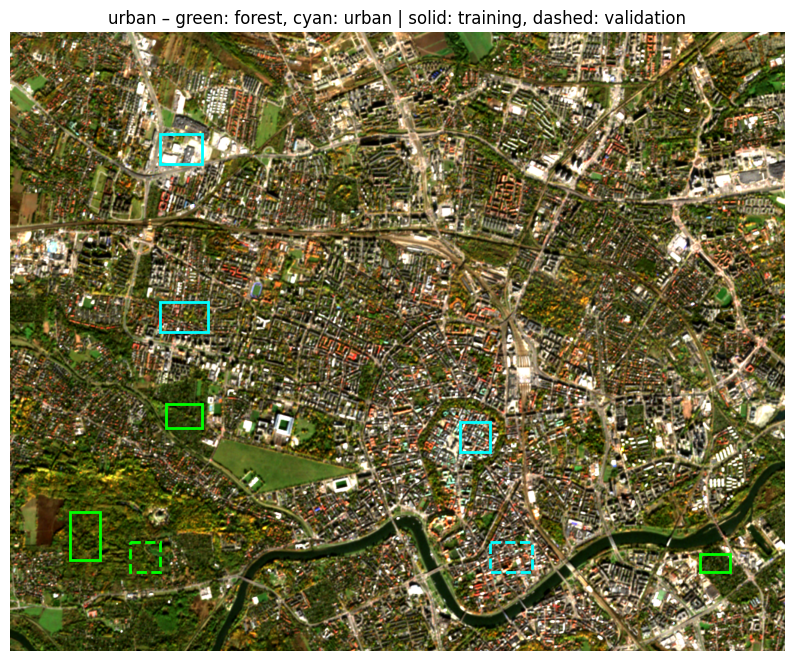

In [45]:
CLASS_COLORS = {"forest": "lime", "urban": "cyan"}

def draw_areas(folder):
    """Shows the image with training (solid) and validation (dashed) rectangles."""
    fig, ax = plt.subplots(figsize=(10, 10))
    ax.imshow(to_rgb(images[folder]))
    for areas, style in [(train_areas, "-"), (val_areas, "--")]:
        for cls, rects in areas.items():
            for img_name, r0, r1, c0, c1 in rects:
                if img_name == folder:
                    ax.add_patch(patches.Rectangle((c0, r0), c1 - c0, r1 - r0, fill=False,
                                                   edgecolor=CLASS_COLORS[cls],
                                                   linestyle=style, linewidth=2))
    ax.set_title(f"{folder} – green: forest, cyan: urban | solid: training, dashed: validation")
    ax.axis('off')
    plt.show()

draw_areas("urban")

Collecting the pixels from each rectangle

In [39]:
def collect_pixels(areas):
    """Returns, for each class, an array of shape (number_of_pixels, number_of_bands)."""
    pixels = {}
    for cls, rects in areas.items():
        pixels[cls] = np.concatenate([
            images[img_name][r0:r1, c0:c1].reshape(-1, len(BANDS))
            for img_name, r0, r1, c0, c1 in rects
        ])
    return pixels

train = collect_pixels(train_areas)
val = collect_pixels(val_areas)

for name, data in [("Training", train), ("Validation", val)]:
    for cls, X in data.items():
        print(f"{name:10} {cls:6}: {X.shape[0]:6d} pixels, {X.shape[1]} bands")

Training   forest:   7900 pixels, 4 bands
Training   urban :   9500 pixels, 4 bands
Validation forest:   2500 pixels, 4 bands
Validation urban :   3500 pixels, 4 bands


## Bayes Classifier
The work on Bayes Classifier starts with parameters definition. I am searching for mu (mean) and sigma (std) for each band of the two classes.

In [46]:
CLASSES = ["forest", "urban"]
PLOT_COLORS = {"forest": "tab:green", "urban": "tab:purple"}

params = {cls: {"mu": train[cls].mean(axis=0), "sigma": train[cls].std(axis=0)}
          for cls in CLASSES}

print(f"{'Class':<8}" + "".join(f"{b + ' mu':>11}{b + ' sigma':>13}" for b in BANDS))
for cls in CLASSES:
    row = "".join(f"{params[cls]['mu'][j]:>11.1f}{params[cls]['sigma'][j]:>13.1f}"
                  for j in range(len(BANDS)))
    print(f"{cls:<8}{row}")

Class        B02 mu    B02 sigma     B03 mu    B03 sigma     B04 mu    B04 sigma     B08 mu    B08 sigma
forest       1078.1        577.6     2729.7        816.4     2515.9        888.6    13555.7       3158.4
urban        2744.4       1676.5     3757.1       1675.8     4094.1       1809.7     8379.7       3544.2


The parameters of the Gaussian model were estimated separately for each class and band as the mean and standard deviation of the training pixels. The forest is darker in all visible bands and brighter in the near-infrared (mean B08 of 13556 compared to 8380 for the city). The city has a two to three times higher standard deviation in the visible bands, reflecting its heterogeneity: dark asphalt, bright roofs, shadows and greenery.

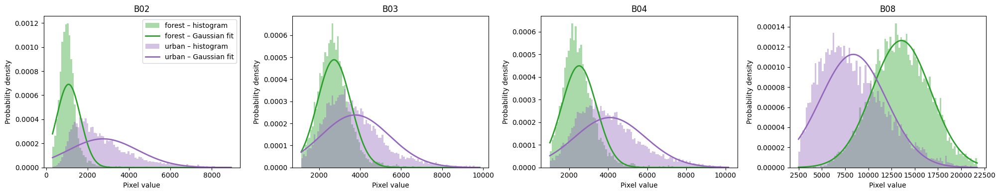

In [47]:
def gaussian_pdf(x, mu, sigma):
    """Normal (Gaussian) probability density function."""
    return np.exp(-0.5 * ((x - mu) / sigma) ** 2) / (sigma * np.sqrt(2 * np.pi))

fig, axes = plt.subplots(1, len(BANDS), figsize=(5 * len(BANDS), 4))
for j, (ax, b) in enumerate(zip(axes, BANDS)):
    all_values = np.concatenate([train[c][:, j] for c in CLASSES])
    edges = np.linspace(*np.percentile(all_values, [0.5, 99.5]), 101)
    x = np.linspace(edges[0], edges[-1], 500)
    for cls in CLASSES:
        ax.hist(train[cls][:, j], bins=edges, density=True, alpha=0.4,
                color=PLOT_COLORS[cls], label=f"{cls} – histogram")
        ax.plot(x, gaussian_pdf(x, params[cls]["mu"][j], params[cls]["sigma"][j]),
                color=PLOT_COLORS[cls], linewidth=2, label=f"{cls} – Gaussian fit")
    ax.set_title(b)
    ax.set_xlabel("Pixel value")
    ax.set_ylabel("Probability density")
axes[0].legend()
plt.tight_layout()
plt.show()

The Gaussian model fits the B08 histograms reasonably well, as both distributions are roughly symmetric. In the visible bands the fit is worse: the forest histograms are narrow and high, so the Gaussian curve underestimates their peak, while the urban histograms are right-skewed with a long tail of bright pixels (roofs, concrete) that the Gaussian does not capture. As observed in Lab02, real distributions are not perfectly Gaussian, so the model is a simplification.

Now I will conduct the Bayes test based on the simple formula. Then I will check the accuracy of each band for each class for further development.

In [48]:
def log_gaussian(x, mu, sigma):
    """Logarithm of the Gaussian PDF (numerically more stable than the PDF itself)."""
    return -0.5 * ((x - mu) / sigma) ** 2 - np.log(sigma * np.sqrt(2 * np.pi))

PRIORS = {"forest": 0.5, "urban": 0.5}

def bayes_1d(x, j):
    """Bayes test using band j. Returns 0 (forest) or 1 (urban) for each value in x."""
    scores = np.stack([log_gaussian(x, params[c]["mu"][j], params[c]["sigma"][j])
                       + np.log(PRIORS[c]) for c in CLASSES], axis=-1)
    return np.argmax(scores, axis=-1)

In [49]:
def evaluate(predict, data):
    """Accuracy of a classifier on labelled pixels: overall and per class."""
    per_class = {cls: (predict(data[cls]) == i).mean() for i, cls in enumerate(CLASSES)}
    n = {cls: len(data[cls]) for cls in CLASSES}
    overall = sum(per_class[c] * n[c] for c in CLASSES) / sum(n.values())
    return overall, per_class

print(f"{'Band':<6}{'overall':>10}{'forest':>10}{'urban':>10}")
for j, b in enumerate(BANDS):
    overall, pc = evaluate(lambda X: bayes_1d(X[:, j], j), val)
    print(f"{b:<6}{overall:>10.1%}{pc['forest']:>10.1%}{pc['urban']:>10.1%}")

Band     overall    forest     urban
B02        88.6%     99.2%     81.0%
B03        64.0%     75.7%     55.7%
B04        78.6%     84.4%     74.4%
B08        84.2%     79.6%     87.4%


B02 gives the highest validation accuracy (88,6%), followed by B08 (84,2%), B04 (78,6%) and B03 (64,0%). B03 performs worst because the forest and urban histograms almost overlap in green light. B02 recognizes the forest almost perfectly, but is weaker for the city, as some urban pixels, such as trees between buildings and shadows, are as dark as the forest. B08 gives more balanced results for both classes. B02 was chosen for the classification, as it has the highest overall accuracy.

Decision boundaries: [1964.5]


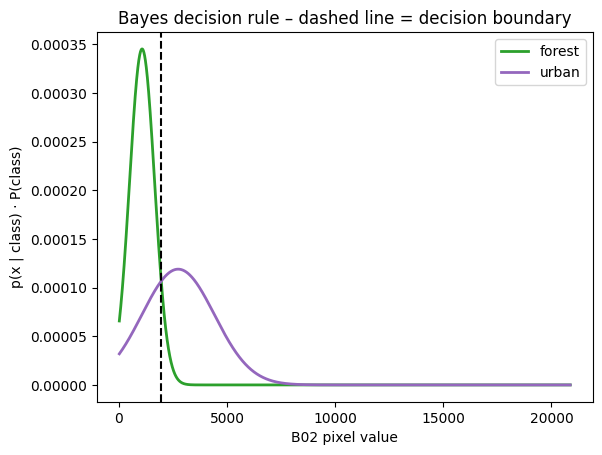

In [56]:
BEST = BANDS.index("B02")

lo = min(train[c][:, BEST].min() for c in CLASSES)
hi = max(train[c][:, BEST].max() for c in CLASSES)
x = np.linspace(lo, hi, 5000)
decision = bayes_1d(x, BEST)
boundaries = x[1:][np.diff(decision) != 0]
print("Decision boundaries:", np.round(boundaries, 1))

for cls in CLASSES:
    plt.plot(x, gaussian_pdf(x, params[cls]["mu"][BEST], params[cls]["sigma"][BEST]) * PRIORS[cls],
             color=PLOT_COLORS[cls], linewidth=2, label=cls)
for bnd in boundaries:
    plt.axvline(bnd, color='black', linestyle='--')
plt.xlabel(f"{BANDS[BEST]} pixel value")
plt.ylabel("p(x | class) · P(class)")
plt.title("Bayes decision rule – dashed line = decision boundary")
plt.legend()
plt.show()

For B02 there is a single decision boundary at about 2000: darker pixels are classified as forest and brighter ones as urban. Since the urban class has an almost three times larger standard deviation, its wide curve could in theory exceed the forest curve again at very low values, creating a second boundary. However, this would only happen at negative values, which do not occur in the data.

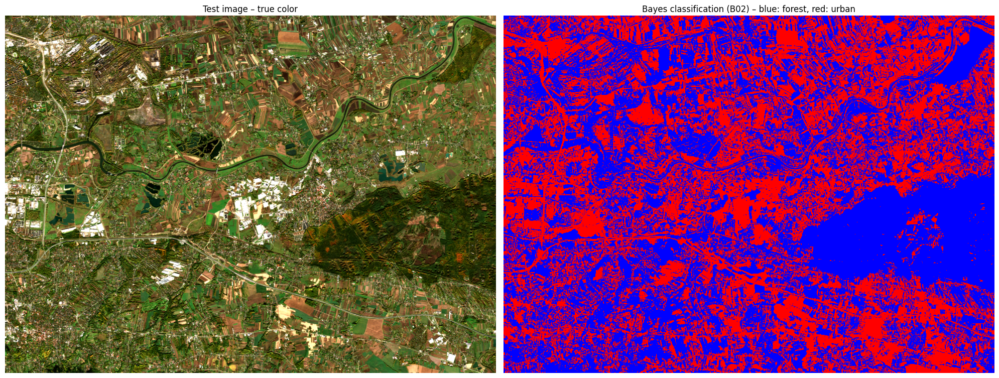

Forest: 52.9% of pixels, urban: 47.1%


In [57]:
from matplotlib.colors import ListedColormap

CLASS_CMAP = ListedColormap(["blue", "red"])   # 0 = forest → blue, 1 = urban → red

test = images["test"]
labels_bayes = bayes_1d(test[..., BEST], BEST)

fig, axes = plt.subplots(1, 2, figsize=(20, 8))
axes[0].imshow(to_rgb(test))
axes[0].set_title("Test image – true color")
axes[1].imshow(labels_bayes, cmap=CLASS_CMAP, vmin=0, vmax=1, interpolation='nearest')
axes[1].set_title(f"Bayes classification ({BANDS[BEST]}) – blue: forest, red: urban")
for a in axes:
    a.axis('off')
plt.tight_layout()
plt.show()

print(f"Forest: {(labels_bayes == 0).mean():.1%} of pixels, urban: {(labels_bayes == 1).mean():.1%}")

What will happen for B08?

Decision boundaries: [10871.8]


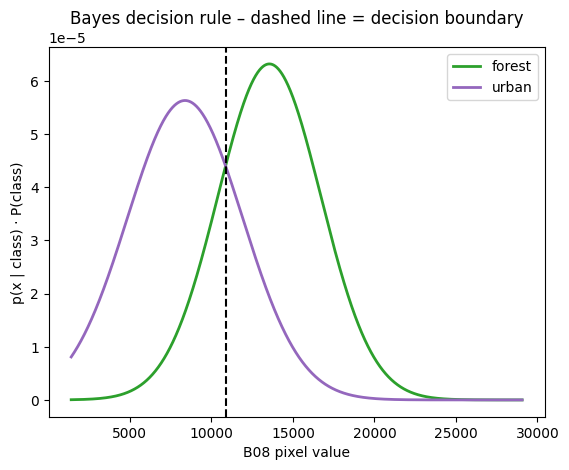

In [58]:
BEST = BANDS.index("B08")

lo = min(train[c][:, BEST].min() for c in CLASSES)
hi = max(train[c][:, BEST].max() for c in CLASSES)
x = np.linspace(lo, hi, 5000)
decision = bayes_1d(x, BEST)
boundaries = x[1:][np.diff(decision) != 0]
print("Decision boundaries:", np.round(boundaries, 1))

for cls in CLASSES:
    plt.plot(x, gaussian_pdf(x, params[cls]["mu"][BEST], params[cls]["sigma"][BEST]) * PRIORS[cls],
             color=PLOT_COLORS[cls], linewidth=2, label=cls)
for bnd in boundaries:
    plt.axvline(bnd, color='black', linestyle='--')
plt.xlabel(f"{BANDS[BEST]} pixel value")
plt.ylabel("p(x | class) · P(class)")
plt.title("Bayes decision rule – dashed line = decision boundary")
plt.legend()
plt.show()

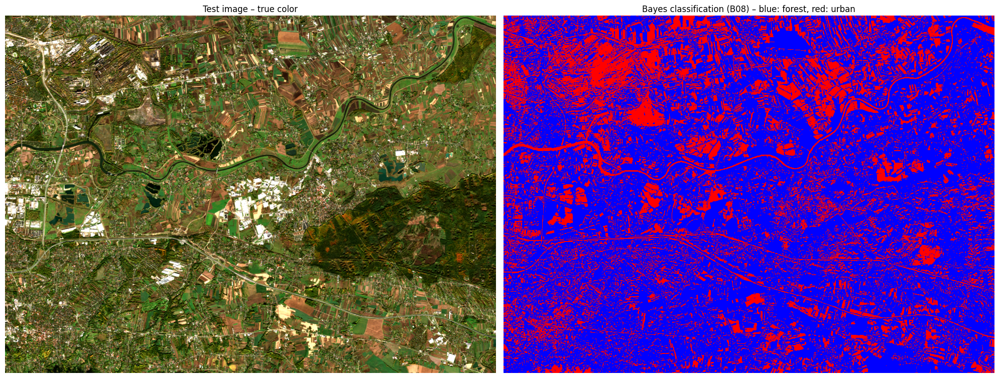

Forest: 70.8% of pixels, urban: 29.2%


In [59]:
from matplotlib.colors import ListedColormap

CLASS_CMAP = ListedColormap(["blue", "red"])   # 0 = forest → blue, 1 = urban → red

test = images["test"]
labels_bayes = bayes_1d(test[..., BEST], BEST)

fig, axes = plt.subplots(1, 2, figsize=(20, 8))
axes[0].imshow(to_rgb(test))
axes[0].set_title("Test image – true color")
axes[1].imshow(labels_bayes, cmap=CLASS_CMAP, vmin=0, vmax=1, interpolation='nearest')
axes[1].set_title(f"Bayes classification ({BANDS[BEST]}) – blue: forest, red: urban")
for a in axes:
    a.axis('off')
plt.tight_layout()
plt.show()

print(f"Forest: {(labels_bayes == 0).mean():.1%} of pixels, urban: {(labels_bayes == 1).mean():.1%}")

For B02, the large forest of Puszcza Niepołomicka is classified as forest almost uniformly, and industrial buildings with bright roofs are classified as urban. Compared to B08 (tested later), the B02 classification separates the forest from green fields and meadows better: in B08 every type of vegetation is bright, so all of it was classified as forest, while in B02 the brighter fields and meadows are mostly classified as urban. Water, however, changed its class: in B08 the river and ponds were classified as urban because water is dark in the near-infrared, while in B02 they are classified as forest because water is also dark in blue light. Villages and suburbs appear as a noisy mixture of both classes, since each pixel is classified independently of its neighbors.

### Insights from the Bayes classifier

* The Bayes classifier turned out to be a simple but effective tool for separating forest from urban areas. All of its knowledge is the mean and standard deviation of each class in the chosen band. The classification itself reduces to a single threshold: for B02, pixels darker than about 2000 are classified as forest and brighter ones as urban. Thanks to this simplicity, the classifier cannot memorize the training data, and its decisions are easy to interpret.

* The choice of band strongly affects the results. Overall validation accuracy ranged from 64,0% for B03 to 88,6% for B02, and the classification maps of B02 and B08 differ noticeably, even though both bands give similar overall accuracy. B08 essentially separates vegetation from non-vegetated surfaces, while B02 is closer to separating forest from other surfaces, as the forest canopy is particularly dark in blue light. The choice of band should therefore be justified by validation results rather than by the appearance of the histograms. Also, the height of the histograms is not a meaningful criterion, as it mainly depends on the range of values in a given band.

* The results also reveal several limitations. The most important one is that the classifier knows only two classes, so every pixel is forced into one of them. The test image is dominated by agricultural fields, meadows and water, which belong to neither class: bright fields are classified as urban, while water and shadows are classified as forest, as they are dark in blue light. For the same reason, the reported shares of forest (52,9%) and urban (47,1%) pixels do not describe the real land cover of the test area. Second, the Gaussian model is only an approximation, as the histograms, especially in the visible bands, are skewed. Third, each pixel is classified independently, which results in a noisy speckle-ish pattern in villages and suburbs.

* The classification could be improved in several ways: by using several bands at once with a multivariate Gaussian model, by introducing more classes such as water, fields and meadows, by taking neighboring pixels into account to reduce noise, or by setting prior probabilities based on the expected share of each class in the area. Although, the exercise was about testing the simplest option.

# kNN Classifier

In [60]:
FEATURES = [0, 1, 2, 3] # band indices used by kNN: B02, B03, B04 and B08
N_PER_CLASS = 500 # training pixels per class
rng = np.random.default_rng(seed=42)

X_train = np.concatenate([
    train[c][rng.choice(len(train[c]), N_PER_CLASS, replace=False)][:, FEATURES]
    for c in CLASSES
])
y_train = np.repeat(np.arange(len(CLASSES)), N_PER_CLASS) # 0 = forest, 1 = urban

feat_mean = X_train.mean(axis=0)
feat_std = X_train.std(axis=0)

def standardize(X):
    """Selects the kNN features and scales each of them to mean 0 and standard deviation 1."""
    return ((X[:, FEATURES] - feat_mean) / feat_std).astype(np.float32)

X_train_s = ((X_train - feat_mean) / feat_std).astype(np.float32)
print("Training set:", X_train_s.shape, "| labels:", np.bincount(y_train))

Training set: (1000, 4) | labels: [500 500]


### How does the kNN Classifier work

kNN classifies a new pixel by comparing it directly with the training pixels. The algorithm consists of the following steps:

1. Preparation of the training data: A random sample of 500 pixels per class is drawn from the training rectangles. Each pixel is described by its values in four bands (B02, B03, B04, B08) and has a label: 0 for forest, 1 for urban. The sample is limited to keep the computation feasible for the whole test image.
2. Standarization the features: Each band is transformed by subtracting its mean and dividing by its standard deviation, both computed from the training data. Without this step, B08, which has much larger values, would dominate the distance.
3. Computing distances: For a new pixel, the Euclidean distance to every training pixel is computed in the four-dimensional space of standardized band values.
4. Finding the k nearest neighbours: The k training pixels with the smallest distances are selected.
5. The result: The pixel is assigned to the class held by the majority of its k neighbours. Using odd values of k avoids ties between two classes.

In the implementation, the five nearest neighbours of each pixel are found once, and the results for k = 1, 3 and 5 are obtained from the same list, which avoids repeating the most expensive step.

In [61]:
K_MAX = 5

def knn_neighbors(X, k_max=K_MAX, chunk=2000):
    """For each pixel in X returns the labels of its k_max nearest training pixels, sorted from the nearest to the farthest."""
    Xs = standardize(X)
    neighbor_labels = np.empty((len(Xs), k_max), dtype=np.int8)
    for start in range(0, len(Xs), chunk):
        part = Xs[start:start + chunk]
        # squared Euclidean distance from every pixel in the chunk to every training pixel
        d = np.sum((part[:, None, :] - X_train_s[None, :, :]) ** 2, axis=-1)
        # indices of the k_max smallest distances (unordered), then ordered by distance
        idx = np.argpartition(d, k_max, axis=1)[:, :k_max]
        order = np.argsort(np.take_along_axis(d, idx, axis=1), axis=1)
        neighbor_labels[start:start + chunk] = y_train[np.take_along_axis(idx, order, axis=1)]
    return neighbor_labels

def knn_vote(neighbor_labels, k):
    """Majority vote among the k nearest neighbors: urban (1) if more than half are urban."""
    return (neighbor_labels[:, :k].sum(axis=1) > k / 2).astype(int)

Classification accuracy:

In [62]:
print(f"{'k':<4}{'overall':>10}{'forest':>10}{'urban':>10}")
for k in [1, 3, 5]:
    overall, pc = evaluate(lambda X: knn_vote(knn_neighbors(X), k), val)
    print(f"{k:<4}{overall:>10.1%}{pc['forest']:>10.1%}{pc['urban']:>10.1%}")

# accuracy on the training pixels themselves
train_sets = {cls: train[cls] for cls in CLASSES}
overall_train, _ = evaluate(lambda X: knn_vote(knn_neighbors(X), 1), train_sets)
print(f"\nk = 1 on all training rectangles: {overall_train:.1%}")

k      overall    forest     urban
1        95.0%     92.3%     96.9%
3        96.2%     95.4%     96.9%
5        96.4%     95.8%     96.8%

k = 1 on all training rectangles: 90.7%


The kNN classifier reaches 95,0–96,4% validation accuracy, depending on k. The accuracy increases with k, but more and more slowly, and almost the whole improvement concerns the forest (from 92,3% to 95,8%), while the urban accuracy stays at about 96,9%.

Surprisingly, k = 1 applied to all pixels of the training rectangles gives a lower accuracy (90,7%) than on the validation data. This is because only 1000 of the training pixels were included in the random sample, so most pixels of the training rectangles were as new to the classifier as the validation pixels. The result rather shows that the training rectangles are more difficult than the validation ones: some of them are mixed, e.g. urban areas with many trees. The validation results are therefore probably too optimistic, and the real accuracy for typical forest and urban areas is likely closer to 90%.

In [63]:
import time

H, W = test.shape[:2]
t0 = time.time()
test_neighbors = knn_neighbors(test.reshape(-1, len(BANDS)))
print(f"Neighbors found in {time.time() - t0:.0f} s")

labels_knn = {k: knn_vote(test_neighbors, k).reshape(H, W) for k in [1, 3, 5]}
for k, lab in labels_knn.items():
    print(f"k = {k}: forest {(lab == 0).mean():.1%}, urban {(lab == 1).mean():.1%}")

Neighbors found in 140 s
k = 1: forest 45.3%, urban 54.7%
k = 3: forest 46.8%, urban 53.2%
k = 5: forest 47.8%, urban 52.2%


Classifying the whole test image took 140 seconds, even though the training set was limited to 1000 pixels, since each of about 4,5 million pixels has to be compared with every training pixel. As k increases, the share of pixels classified as forest grows from 45,3% to 47,8%. As with the Bayes classifier, these shares do not describe the real land cover, since fields, meadows and water are forced into one of the two classes.

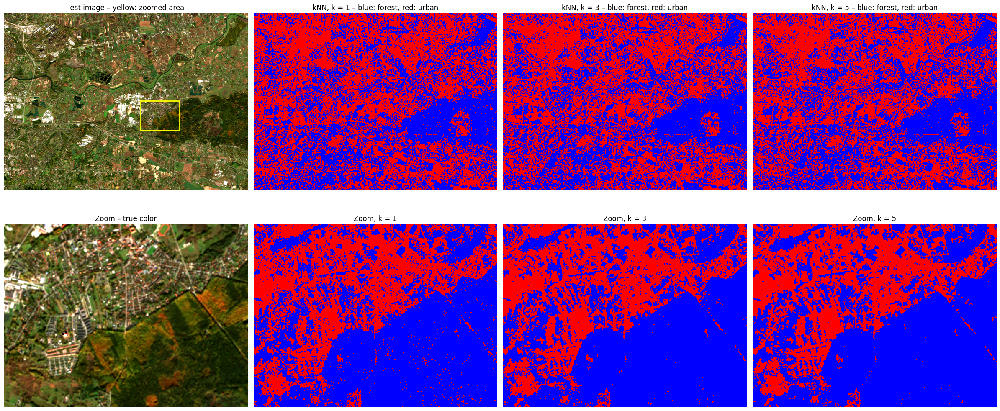

In [65]:
r0, r1, c0, c1 = 900, 1200, 1400, 1800 #zoom

fig, axes = plt.subplots(2, 4, figsize=(24, 11))
axes[0, 0].imshow(to_rgb(test))
axes[0, 0].add_patch(patches.Rectangle((c0, r0), c1 - c0, r1 - r0,
                                       fill=False, edgecolor='yellow', linewidth=2))
axes[0, 0].set_title("Test image – yellow: zoomed area")
axes[1, 0].imshow(to_rgb(test)[r0:r1, c0:c1])
axes[1, 0].set_title("Zoom – true color")

for col, k in enumerate([1, 3, 5], start=1):
    axes[0, col].imshow(labels_knn[k], cmap=CLASS_CMAP, vmin=0, vmax=1, interpolation='nearest')
    axes[0, col].set_title(f"kNN, k = {k} – blue: forest, red: urban")
    axes[1, col].imshow(labels_knn[k][r0:r1, c0:c1], cmap=CLASS_CMAP, vmin=0, vmax=1,
                        interpolation='nearest')
    axes[1, col].set_title(f"Zoom, k = {k}")

for a in axes.flat:
    a.axis('off')
plt.tight_layout()
plt.show()

The Puszcza Niepołomicka forest on the right is classified as forest for all values of k, and the forest boundary is clearly visible in the zoomed fragment. The main difference between the maps is their noisiness: for k = 1 the map contains many isolated pixels of the other class, while for k = 3 and k = 5 the patches become larger and more coherent. The red patch inside the forest corresponds to an orange area in the true color image, which may be autumn leaves or a clearing, and is classified as urban by both classifiers (as it's different from the forest it knows).

In [66]:
print("Share of pixels with a different class:")
for a, b in [(1, 3), (1, 5), (3, 5)]:
    print(f"  k = {a} vs k = {b}: {(labels_knn[a] != labels_knn[b]).mean():.2%}")

print("\nAgreement with the Bayes classifier (B02):")
for k in [1, 3, 5]:
    print(f"  k = {k}: {(labels_knn[k] == labels_bayes).mean():.1%}")

Share of pixels with a different class:
  k = 1 vs k = 3: 8.23%
  k = 1 vs k = 5: 9.56%
  k = 3 vs k = 5: 5.07%

Agreement with the Bayes classifier (B02):
  k = 1: 63.8%
  k = 3: 66.0%
  k = 5: 67.1%


Changing k from 1 to 3 changes the class of 8,2% of the pixels, while changing it from 3 to 5 changes only 5,1%, so the largest difference appears when moving from a single neighbour to voting. This is consistent with the growing share of forest: some training pixels labelled as urban are in fact trees within the city. With k = 1, such a single pixel can decide the class of a forest pixel, while with larger k it is outvoted by its forest neighbours. The agreement with the Bayes classifier is only 64–67%. The disagreement mostly concerns fields, meadows and water, which belong to neither class, so each classifier assigns them according to its own logic, while for clear forest and urban areas both classifiers agree.

### Insights from the kNN classifier

* The kNN classifier does not assume any model of the data and classifies each pixel by comparing it directly with the training pixels, which allows it to use all four bands at once. It reached a validation accuracy of about 96%, although this value is probably optimistic, as the validation rectangles are purer than typical forest and urban areas.

* The value of k controls how sensitive the classifier is to individual training pixels. With k = 1, a single atypical or mislabelled pixel, such as a tree within an urban training rectangle, can decide the class, which results in a noisy map and a lower accuracy for the forest. With k = 3 and k = 5, such pixels are outvoted, the map becomes smoother and the accuracy slightly increases. The improvement gets smaller with each increase of k, and the largest change occurs when moving from a single neighbour to voting.

* The main drawback of kNN is its computational cost. It does not learn any parameters in advance, but postpones all the work until classification, so each new pixel has to be compared with every training pixel. Even with the training set reduced to 1000 pixels, classifying the test image took over two minutes, and the time grows with the size of the training set.

## Comparison and conclusions

* Both classifiers separate forest from urban areas, but they work in different ways. The Bayes classifier summarizes the training data in a few parameters and classifies the whole image almost instantly, with easily interpretable decisions, e.g. a single threshold in B02. The kNN classifier keeps all training pixels and compares each new pixel with them, which makes it slower, but allows it to capture more complex relationships without assuming any distribution. In this task, kNN achieved a higher validation accuracy (about 96% compared to 88,6%), but the comparison is not entirely fair, as kNN used four bands while the Bayes classifier used only one.

* Both classifiers share the same main limitation: they know only two classes. The test image is dominated by fields, meadows and water, which are forced into the forest or urban class, and this is where the two classifiers disagree the most. Both also classify each pixel independently, which results in noisy maps in villages and suburbs. The results could be improved by adding more classes, using more bands in the Bayes classifier and taking neighbouring pixels into account. Finally, the quality of both classifiers strongly depends on the training data: mixed training areas, such as cities with many trees, directly affect the decisions, which shows that careful selection of training samples is as important as the choice of the classification method.